# Maze Solver: Comparing BFS, DFS and A* Pathfinding
 
**Objective:** Generate a random maze and compare three pathfinding algorithms (BFS, DFS, A*) on path length, cells explored and execution time.  
**Concepts:** Graphs, Backtracking, Queue, Stack, Priority Queue (Heap), Heuristics, Time Complexity  
**Tools:** Python, NumPy, Matplotlib, Jupyter Notebook

In [1]:
import random                    
import time                      
import heapq                     
from collections import deque    
import numpy as np               
import matplotlib.pyplot as plt  

## Section 2: Maze Generation (DFS Backtracking)
The maze is a 2D grid: 1 = wall, 0 = open path. Each open cell is a node of a graph,
and two neighbouring open cells are joined by an edge.

In [2]:
def generate_maze(n, seed=None, loops=0.10):
    random.seed(seed)                     
    size = 2 * n + 1                       
    maze = np.ones((size, size), dtype=int) 
    maze[1, 1] = 0                          
    stack = [(1, 1)]                        

    while stack:
        r, c = stack[-1]                    
        options = [(r + dr, c + dc) for dr, dc in [(-2, 0), (2, 0), (0, -2), (0, 2)]
                   if 0 < r + dr < size - 1 and 0 < c + dc < size - 1
                   and maze[r + dr, c + dc] == 1]
        if options:
            nr, nc = random.choice(options)        
            maze[(r + nr) // 2, (c + nc) // 2] = 0 
            maze[nr, nc] = 0                      
            stack.append((nr, nc))
        else:
            stack.pop()                            

    walls = [(r, c) for r in range(1, size - 1) for c in range(1, size - 1)
             if maze[r, c] == 1 and (r % 2) != (c % 2)]
    for r, c in random.sample(walls, int(len(walls) * loops)):
        maze[r, c] = 0
    return maze

maze = generate_maze(15, seed=42)
START = (1, 1)                                  
END = (maze.shape[0] - 2, maze.shape[1] - 2)     
print("Maze size:", maze.shape)
print("Open cells:", np.sum(maze == 0), "| Walls:", np.sum(maze == 1))


Maze size: (31, 31)
Open cells: 468 | Walls: 493


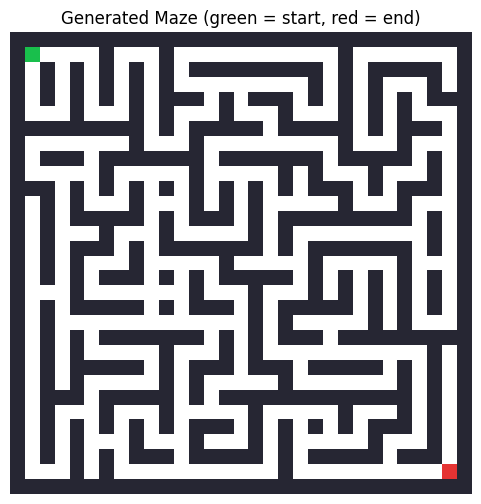

In [3]:
def show_maze(maze, path=None, explored=None, title="Maze", ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    img = np.ones((*maze.shape, 3))             
    img[maze == 1] = [0.15, 0.15, 0.20]          
    for r, c in (explored or []):
        img[r, c] = [0.70, 0.82, 1.00]           
    for r, c in (path or []):
        img[r, c] = [1.00, 0.70, 0.00]           
    img[START] = [0.10, 0.75, 0.30]              
    img[END] = [0.90, 0.20, 0.20]                
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

show_maze(maze, title="Generated Maze (green = start, red = end)")
plt.show()

## Section 3: Pathfinding Algorithms
- **BFS:** explores level by level using a Queue. Always finds the shortest path.
- **DFS:** goes deep first using a Stack. Finds a path, but not always the shortest.
- **A\*:** uses a Priority Queue with f(n) = g(n) + h(n), where h is the Manhattan distance to the goal.
  It finds the shortest path while exploring fewer cells.

In [4]:
def get_neighbors(maze, cell):
    r, c = cell
    result = []
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:   
        nr, nc = r + dr, c + dc
        if maze[nr, nc] == 0:                          
            result.append((nr, nc))
    return result

def build_path(parent, end):
    if end not in parent:
        return []                                     
    path = [end]
    while parent[path[-1]] is not None:                 
        path.append(parent[path[-1]])
    return path[::-1]                                   

In [5]:
def bfs(maze, start, end):
    queue = deque([start])          
    parent = {start: None}          
    explored = []
    while queue:
        cell = queue.popleft()
        explored.append(cell)
        if cell == end:
            break
        for nb in get_neighbors(maze, cell):
            if nb not in parent:
                parent[nb] = cell
                queue.append(nb)
    return build_path(parent, end), explored

In [6]:
def dfs(maze, start, end):
    stack = [(start, None)]         
    parent = {}
    explored = []
    while stack:
        cell, par = stack.pop()
        if cell in parent:         
            continue
        parent[cell] = par
        explored.append(cell)
        if cell == end:
            break
        for nb in get_neighbors(maze, cell):
            if nb not in parent:
                stack.append((nb, cell))
    return build_path(parent, end), explored

In [7]:
def heuristic(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])   

def astar(maze, start, end):
    heap = [(heuristic(start, end), 0, start)]   
    g = {start: 0}                               
    parent = {start: None}
    done = set()
    explored = []
    while heap:
        f, cost, cell = heapq.heappop(heap)
        if cell in done:
            continue
        done.add(cell)
        explored.append(cell)
        if cell == end:
            break
        for nb in get_neighbors(maze, cell):
            new_cost = g[cell] + 1
            if new_cost < g.get(nb, float("inf")):   
                g[nb] = new_cost
                parent[nb] = cell
                heapq.heappush(heap, (new_cost + heuristic(nb, end), new_cost, nb))
    return build_path(parent, end), explored

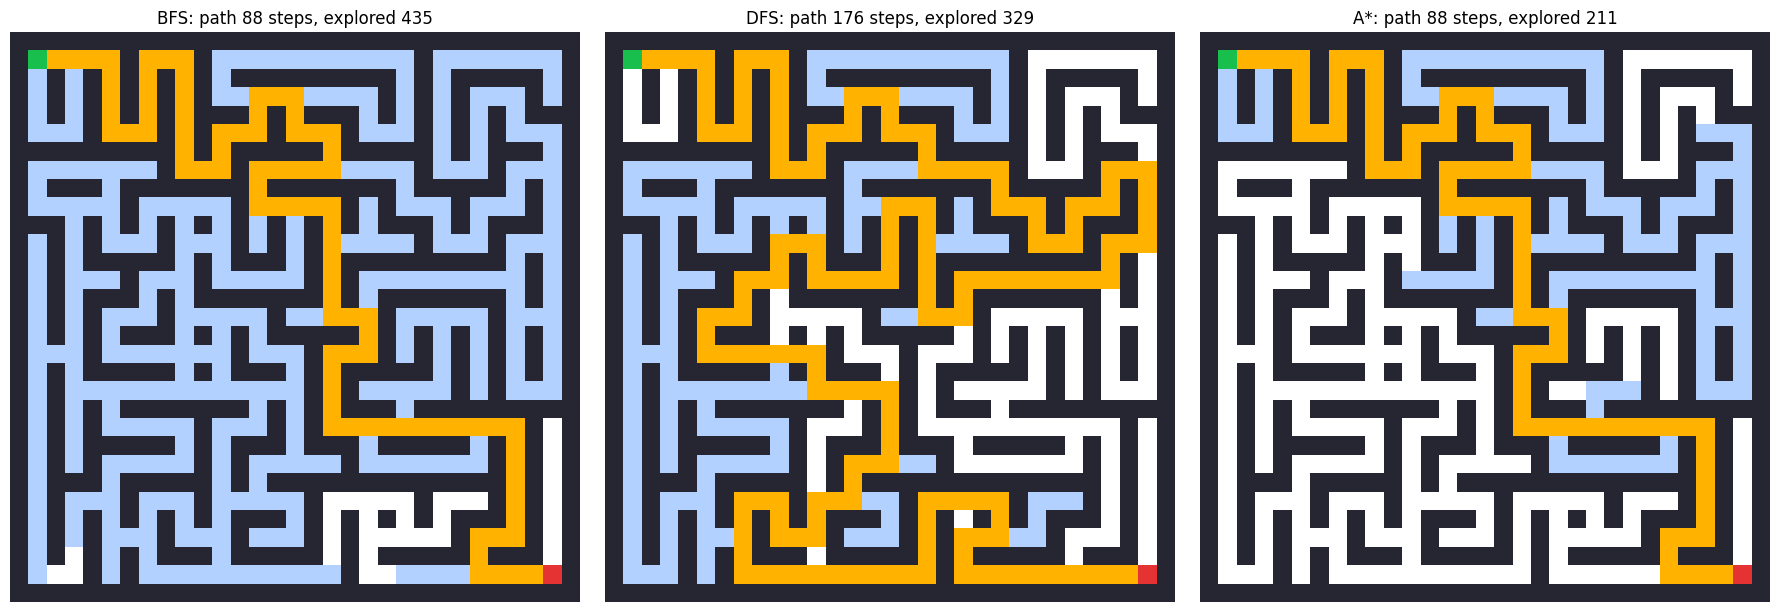

In [8]:
algorithms = {"BFS": bfs, "DFS": dfs, "A*": astar}

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, func) in zip(axs, algorithms.items()):
    path, explored = func(maze, START, END)
    show_maze(maze, path, explored,
              f"{name}: path {len(path) - 1} steps, explored {len(explored)}", ax)
plt.tight_layout()
plt.savefig("paths.png", dpi=150, bbox_inches="tight")  
plt.show()

## Section 4: Comparison on the Same Maze

Algorithm    Time (ms)    Explored   Path length
------------------------------------------------
BFS              1.308         435            88
DFS              1.612         329           176
A*               2.118         211            88


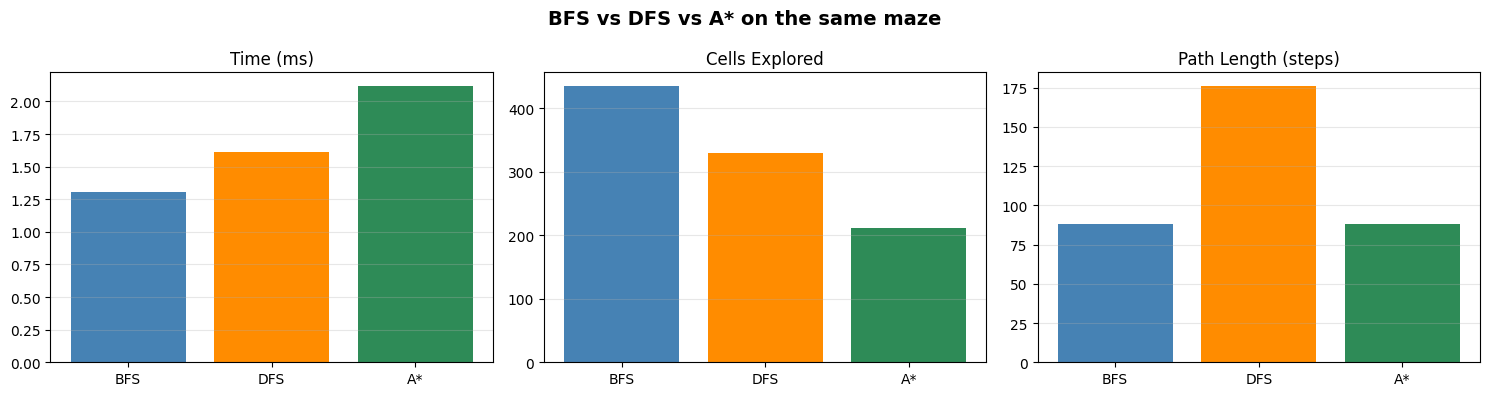

In [9]:
results = []
for name, func in algorithms.items():
    t0 = time.perf_counter()
    path, explored = func(maze, START, END)
    ms = (time.perf_counter() - t0) * 1000          
    results.append((name, ms, len(explored), len(path) - 1))

print(f"{'Algorithm':<10}{'Time (ms)':>12}{'Explored':>12}{'Path length':>14}")
print("-" * 48)
for name, ms, exp, steps in results:
    print(f"{name:<10}{ms:>12.3f}{exp:>12}{steps:>14}")

names = [r[0] for r in results]
colors = ["steelblue", "darkorange", "seagreen"]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, idx, title in zip(axs, [1, 2, 3], ["Time (ms)", "Cells Explored", "Path Length (steps)"]):
    ax.bar(names, [r[idx] for r in results], color=colors)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("BFS vs DFS vs A* on the same maze", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 5: Performance Analysis (Time vs Maze Size)

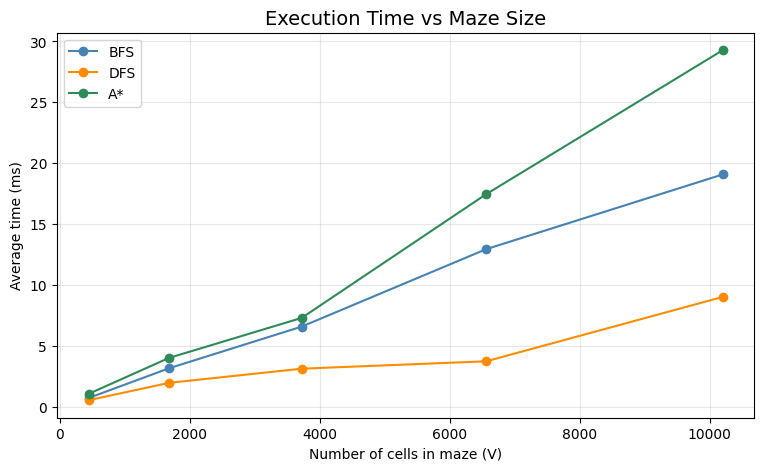

In [10]:
sizes = [10, 20, 30, 40, 50]
times = {name: [] for name in algorithms}

for n in sizes:
    for name, func in algorithms.items():
        total = 0
        for trial in range(5):                        
            m = generate_maze(n, seed=trial)
            end = (m.shape[0] - 2, m.shape[1] - 2)
            t0 = time.perf_counter()
            func(m, START, end)
            total += time.perf_counter() - t0
        times[name].append(total / 5 * 1000)

cells = [(2 * n + 1) ** 2 for n in sizes]              
plt.figure(figsize=(9, 5))
for (name, t), col in zip(times.items(), colors):
    plt.plot(cells, t, marker="o", color=col, label=name)
plt.title("Execution Time vs Maze Size", fontsize=14)
plt.xlabel("Number of cells in maze (V)")
plt.ylabel("Average time (ms)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("performance.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 6: Key Insights

| Algorithm | Data Structure | Time Complexity | Shortest Path? |
|---|---|---|---|
| Maze generation (DFS backtracking) | Stack | O(V) | - |
| BFS | Queue | O(V + E) | Yes |
| DFS | Stack | O(V + E) | No |
| A* | Priority Queue (Heap) | O(E log V) | Yes (admissible heuristic) |

1. **BFS and A\*** both found the shortest path (88 steps). **DFS** found a path twice as long (176 steps).
2. **A\*** explored only 211 cells, about half of BFS (435), because the heuristic guides it towards the goal.
3. **DFS** is fast and explores fewer cells than BFS, but gives no shortest-path guarantee.
4. Time grows roughly linearly with the number of cells, matching the theoretical complexity.

## Conclusion
A* is the best choice for finding the shortest path efficiently. BFS is simple and always correct
but explores more. DFS is useful only when any path is enough. The same algorithms are used in
GPS navigation, game AI and robot path planning.